In [26]:
import os
import copy
import pickle as pkl
import pandas as pd
from tqdm import tqdm
import random as random
import numpy as np
from ray import tune
import datasets
import numpy as np
from datasets import load_metric

from transformers import AutoTokenizer, AutoModel
from transformers import AutoModelForSequenceClassification
from transformers import TrainingArguments, Trainer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV
from sklearn import metrics
from sklearn.pipeline import Pipeline

In [2]:
    neg_to_pos_ratio = 1

    results_file = "results_titles_abstracts_gbdt.json"

    inputs = "titles_abstracts"

    filename_pos_human = "../data/pubmed_articles_pos_human.csv"
    filename_neg_human = "../data/pubmed_articles_neg_human.csv"

    with open("../data/cleaned_pos_neg_train_val_test_dataset_ids.pkl", "rb") as f:
        prop_typ_id_dict = pkl.load(f)
    ptype = 'is_consensus'



In [3]:
            pos_data_human = pd.read_csv(filename_pos_human, chunksize=100000)
            neg_data_human = pd.read_csv(filename_neg_human, chunksize=100000)

            pos_train_ids = prop_typ_id_dict[ptype]["pos"]["train"]
            neg_train_ids = prop_typ_id_dict[ptype]["neg"]["train"]

            pos_val_ids = prop_typ_id_dict[ptype]["pos"]["val"]
            neg_val_ids = prop_typ_id_dict[ptype]["neg"]["val"]

            pos_test_ids = prop_typ_id_dict[ptype]["pos"]["test"]
            neg_test_ids = prop_typ_id_dict[ptype]["neg"]["test"]

            pos_train_set = pd.DataFrame()
            pos_val_set = pd.DataFrame()
            pos_test_set = pd.DataFrame()

            for pos_chunk in tqdm(pos_data_human):

                indices = pos_chunk.index
                indices = list(indices)

                pos_train_indices = list(
                    set(indices).intersection(set(pos_train_ids))
                )
                pos_val_indices = list(set(indices).intersection(set(pos_val_ids)))
                pos_test_indices = list(set(indices).intersection(set(pos_test_ids)))

                pos_train_subset = pos_chunk.loc[pos_train_indices]
                if pos_train_set.empty:
                    pos_train_set = pd.DataFrame(columns=pos_train_set.columns)
                pos_train_set = pd.concat([pos_train_set, pos_train_subset])

                pos_val_subset = pos_chunk.loc[pos_val_indices]
                if pos_val_set.empty:
                    pos_val_set = pd.DataFrame(columns=pos_val_set.columns)
                pos_val_set = pd.concat([pos_val_set, pos_val_subset])

                pos_test_subset = pos_chunk.loc[pos_test_indices]
                if pos_test_set.empty:
                    pos_test_set = pd.DataFrame(columns=pos_test_set.columns)
                pos_test_set = pd.concat([pos_test_set, pos_test_subset])

            pos_train_set[ptype] = int(1)
            pos_val_set[ptype] = int(1)
            pos_test_set[ptype] = int(1)

            del pos_data_human
            del pos_train_subset
            del pos_chunk
            del indices
            del pos_train_ids

            neg_train_ids_sample = random.sample(
                neg_train_ids, round(len(pos_train_set) * neg_to_pos_ratio)
            )

            neg_train_set = pd.DataFrame()
            neg_val_set = pd.DataFrame()
            neg_test_set = pd.DataFrame()

            for neg_chunk in tqdm(neg_data_human):

                indices = neg_chunk.index
                indices = list(indices)
                neg_train_indices = list(
                    set(indices).intersection(set(neg_train_ids_sample))
                )
                neg_val_indices = list(set(indices).intersection(set(neg_val_ids)))
                neg_test_indices = list(set(indices).intersection(set(neg_test_ids)))
                neg_subset = neg_chunk.loc[indices]

                neg_train_subset = neg_chunk.loc[neg_train_indices]
                if neg_train_set.empty:
                    neg_train_set = pd.DataFrame(columns=neg_train_set.columns)
                neg_train_set = pd.concat([neg_train_set, neg_train_subset])

                neg_val_subset = neg_chunk.loc[neg_val_indices]
                if neg_val_set.empty:
                    neg_val_set = pd.DataFrame(columns=neg_val_set.columns)
                neg_val_set = pd.concat([neg_val_set, neg_val_subset])

                neg_test_subset = neg_chunk.loc[neg_test_indices]
                if neg_test_set.empty:
                    neg_test_set = pd.DataFrame(columns=neg_test_set.columns)
                neg_test_set = pd.concat([neg_test_set, neg_test_subset])

            neg_train_set[ptype] = int(0)
            neg_val_set[ptype] = int(0)
            neg_test_set[ptype] = int(0)

            del neg_data_human
            del neg_subset
            del neg_chunk
            del indices

            train_data = pd.concat([neg_train_set, pos_train_set]).sample(
                frac=1
            )
            del neg_train_set
            del pos_train_set
            val_data = pd.concat([neg_val_set, pos_val_set]).sample(frac=1)
            del neg_val_set
            del pos_val_set
            test_data = pd.concat([neg_test_set, pos_test_set]).sample(frac=1)
            del neg_test_set
            del pos_test_set

            y_train = train_data[ptype]
            y_val = val_data[ptype]
            y_test = test_data[ptype]
            if inputs == "abstracts":
                X_train = train_data["abstract_plaintext"]
                X_val = val_data["abstract_plaintext"]
                X_test = test_data["abstract_plaintext"]
            elif inputs == "titles":
                X_train = train_data["title"]
                X_val = val_data["title"]
                X_test = test_data["title"]
            elif inputs == "titles_abstracts":
                X_train_titles = train_data["title"]
                X_train_abstracts = train_data["abstract_plaintext"]
                
                X_val_titles = val_data["title"]
                X_val_abstracts = val_data["abstract_plaintext"]
                
                X_test_titles = test_data["title"]
                X_test_abstracts = test_data["abstract_plaintext"]

            del train_data
            del val_data
            del test_data

19it [00:24,  1.33s/it]/home/k2141255/anaconda3/envs/study_design_classifier/lib/python3.8/site-packages/tqdm/std.py:1195: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  for obj in iterable:
51it [01:11,  1.58s/it]/home/k2141255/anaconda3/envs/study_design_classifier/lib/python3.8/site-packages/tqdm/std.py:1195: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  for obj in iterable:
86it [01:59,  1.39s/it]
57it [01:31,  1.60s/it]


In [4]:
# load model and tokenizer
tokenizer = AutoTokenizer.from_pretrained('malteos/scincl')
model = AutoModel.from_pretrained('malteos/scincl').to("cuda")

In [16]:
title_abs = [t + tokenizer.sep_token + (a or '') for t, a in zip(X_train_titles, X_train_abstracts)]
inputs = tokenizer(title_abs, padding=True, truncation=True, return_tensors="pt", max_length=512).to("cuda")

In [56]:
train_embeddings = []
batch_size = 16
for i in tqdm(range(len(X_train_titles)//batch_size)):
    
    batch_inputs = {
        "input_ids": inputs['input_ids'][i*batch_size:(i+1)*batch_size],
        "token_type_ids": inputs['token_type_ids'][i*batch_size:(i+1)*batch_size],
        "attention_mask": inputs['attention_mask'][i*batch_size:(i+1)*batch_size]
    }
    
    # inference
    result = model(**batch_inputs)

    # take the first token ([CLS] token) in the batch as the embedding
    embedding = result.last_hidden_state[:, 0, :].to("cpu").detach().numpy()
    train_embeddings.append(embedding)

100%|█████████████████████████████████████████| 620/620 [01:08<00:00,  9.09it/s]


In [59]:
i

619

In [57]:
train_embeddings = np.concatenate(train_embeddings)

In [58]:
train_embeddings.shape

(9920, 768)

In [77]:
title_abs = [t + tokenizer.sep_token + (a or '') for t, a in zip(X_val_titles, X_val_abstracts)]
inputs = tokenizer(title_abs, padding=True, truncation=True, return_tensors="pt", max_length=512).to("cuda") 

In [78]:
val_embeddings = []
batch_size = 16
for i in tqdm(range(len(X_val_titles)//batch_size)):
    
    batch_inputs = {
        "input_ids": inputs['input_ids'][i*batch_size:(i+1)*batch_size],
        "token_type_ids": inputs['token_type_ids'][i*batch_size:(i+1)*batch_size],
        "attention_mask": inputs['attention_mask'][i*batch_size:(i+1)*batch_size]
    }
    
    # inference
    result = model(**batch_inputs)

    # take the first token ([CLS] token) in the batch as the embedding
    embedding = result.last_hidden_state[:, 0, :].to("cpu").detach().numpy()
    val_embeddings.append(embedding)

    

100%|█████████████████████████████████████| 16897/16897 [31:11<00:00,  9.03it/s]


In [79]:
val_embeddings = np.concatenate(val_embeddings)

In [80]:
len(X_val_titles)

270360

In [27]:
clf = SGDClassifier(loss="log", penalty="l2", alpha=0.0001)

In [61]:
clf.fit(train_embeddings, y_train)

SGDClassifier(loss='log')

In [81]:
labels_pred = clf.predict(val_embeddings)

In [85]:
labels_val = np.array(y_val[:270352])

In [86]:
len(val_embeddings)

270352

In [87]:
print('precision',metrics.precision_score(labels_pred, labels_val))
print('recall',metrics.recall_score(labels_pred, labels_val))
print('f1',metrics.f1_score(labels_pred, labels_val))
print('accuracy',metrics.accuracy_score(labels_pred, labels_val))
print('AUC ROC',metrics.roc_auc_score(labels_pred, labels_val))
print(len(labels_val))

precision 0.802536231884058
recall 0.02794071270892463
f1 0.05400134089108307
accuracy 0.9425896608865479
AUC ROC 0.5137562084470213
270352


/home/k2141255/anaconda3/envs/study_design_classifier/lib/python3.8/site-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function plot_roc_curve is deprecated; Function :func:`plot_roc_curve` is deprecated in 1.0 and will be removed in 1.2. Use one of the class methods: :meth:`sklearn.metric.RocCurveDisplay.from_predictions` or :meth:`sklearn.metric.RocCurveDisplay.from_estimator`.
  warnings.warn(msg, category=FutureWarning)


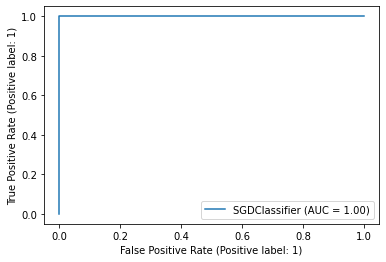

In [89]:
metrics.plot_roc_curve(clf, np.array(val_embeddings), labels_pred.reshape(-1,1)) 